## Imports

### 导入必备的库

In [1]:
#Import libraries
import os
import random
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# Image manipulation
from PIL import Image

# PyTorch libraries
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import torchvision
import torch.nn.functional as F
import torch.optim as optim
from torchinfo import summary
from torch.optim.lr_scheduler import ReduceLROnPlateau

import albumentations as A
from albumentations.pytorch import ToTensorV2

from tqdm.auto import tqdm

import segmentation_models_pytorch as smp
from segmentation_models_pytorch.losses import DiceLoss, JaccardLoss



### 拆分各个功能模块
为了保持主 Notebook 逻辑清晰、易于维护，将训练、评估和绘图等辅助功能拆分到了独立的.py 文件中
- compute_accuracy_loss：用于计算验证集的损失值（Loss）和像素准确率（Accuracy）。
- check_metrics：用于计算图像分割任务的专用评估指标（如 Dice 系数、IoU 等）。
- train_model：封装了完整的训练循环逻辑（包含前向传播、损失计算、反向传播及参数更新）。
- plot_loss_accuracy 与 plot_img_mask_pred：分别用于绘制训练过程中的损失/准确率曲线，以及可视化输入图像、真实掩膜和预测掩膜的对比效果

In [2]:
# From local helper files
from helper_evaluation import compute_accuracy_loss
from helper_metrics import check_metrics
from helper_train import train_model
from helper_plotting import plot_loss_accuracy,  plot_img_mask_pred

### 配置核心超参数
- device：自动检测硬件环境。优先使用 GPU (cuda)，若不可用则回退至 CPU。关键点：GPU 加速能将数小时的训练时间压缩至几十分钟。
- learning_rate (学习率)：设为 5e-4，这是 Adam 优化器在类似视觉任务中常用的量级，用于控制参数更新的步长。
- batch_size (批次大小)：设为 16。在输入图像尺寸为 128x128 的情况下，此大小能较好地平衡显存占用与梯度下降的稳定性。
- epochs (训练轮数)：设为 50，给予模型充足的时间以充分收敛。
- size (图像尺寸)：统一缩放至 (128, 128)。适当降低图像分辨率，换取更大的批次处理能力和更快的运算速度，同时保留足够的病变纹理特征。

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
learning_rate =5e-4
batch_size = 16
epochs = 50
size =(128,128)

In [4]:
device # 验证是否正确调用NVIDIA显卡，验证硬件加速条件是否满足

device(type='cuda')

###  数据加载
将磁盘上的训练图像和对应掩膜文件路径分别读取到两个有序列表（image_paths 和 gt_paths）中，供后续 Dataset 类按索引获取样本
- 文件过滤：通过 .endswith(".jpg") 和 .endswith(".png") 精确匹配文件格式，避免混入无关文件。
- 排序：使用 sorted() 确保两个列表的文件顺序一致（因为图像与掩膜命名规则相同，排序后索引一一对应），防止样本配对错乱。
- 路径拼接：使用 os.path.join 保证跨平台兼容性（Windows/Linux 路径分隔符自动适配）。

In [5]:
import os
print(os.getcwd())

print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0))  # 再次验证是否满足硬件加速

C:\workplace\github\unet\ISIC-2016-lesion-segmentation-challenge
True
NVIDIA GeForce RTX 5070 Ti


In [6]:
# Define the base directory where images and ground truth data are stored
base_dir = './data/'

# Define the subdirectories for images and ground truth
image_folder = "ISBI2016_ISIC_Part1_Training_Data"
gt_folder = "ISBI2016_ISIC_Part1_Training_GroundTruth"

# Combine the base directory with subdirectories
image_dir = os.path.join(base_dir, image_folder)
gt_dir = os.path.join(base_dir, gt_folder)

# Get paths to the training and target images
image_paths = sorted([os.path.join(image_dir, fname)
                      for fname in os.listdir(image_dir)
                      if fname.endswith(".jpg")])
gt_paths = sorted([os.path.join(gt_dir, fname)
                    for fname in os.listdir(gt_dir)
                    if fname.endswith(".png")])

# Check if dimensions are equal
print("Number of samples in the image folder:", len(image_paths))
print("Number of samples in the mask folder:", len(gt_paths))

Number of samples in the image folder: 900
Number of samples in the mask folder: 900


### U‑Net 数据可视化
- 验证数据加载的正确性：通过可视化训练集中的第一张皮肤镜图像及其对应的分割掩膜，确认图像与掩膜的尺寸一致、内容匹配，并初步了解病变区域的形态特征。
- 直观感受数据：为后续预处理（如归一化、增强）和模型设计提供视觉参考。

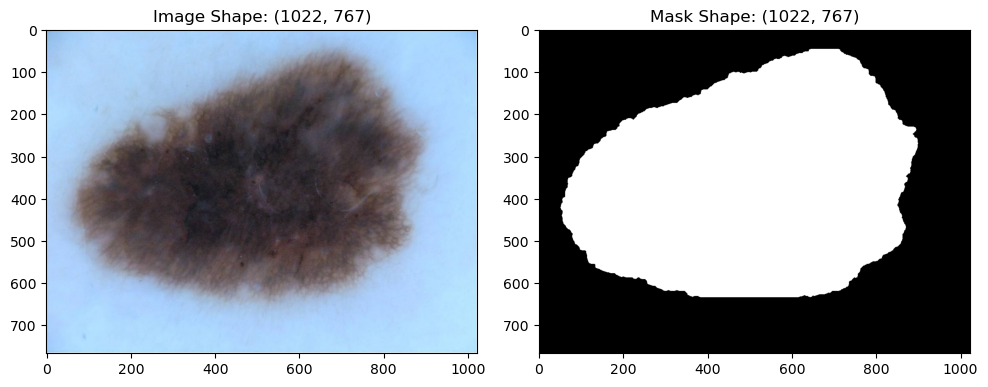

In [7]:
# Define the paths to your image and segmentation mask

# 分别取出列表中的第一个图像路径和第一个掩膜路径，确保索引对应（因为两个列表均按相同规则排序）。
image_path = image_paths[0]
mask_path = gt_paths[0]

# 使用 Pillow 库读取图像和掩膜文件，返回 PIL Image 对象
image = Image.open(image_path)
mask = Image.open(mask_path)

# 获取图像的宽度和高度（单位：像素），用于检查尺寸是否匹配（通常应为相同尺寸，例如 1024×768）
image_shape = image.size  # Returns (width, height)
mask_shape = mask.size    # Returns (width, height)

# 将图像和掩膜转换为 NumPy 数组，方便 Matplotlib 绘图
image_array = plt.imread(image_path)
mask_array = plt.imread(mask_path)

# 创建一行两列的子图，左侧显示原始图像，右侧显示掩膜
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(image_array)
plt.title(f"Image Shape: {image_shape}")

# 子图2
plt.subplot(1, 2, 2)
plt.imshow(mask_array, cmap='gray')  # Assuming the mask is grayscale
plt.title(f"Mask Shape: {mask_shape}")

plt.tight_layout()
plt.show()

### U‑Net 数据准备与加载流水线

In [8]:
percentage_test = 0.05
percentage_validation = 0.1

# 设置随机种子
random_seed = 142

# 分出测试集
image_paths_trainval, image_paths_test, mask_paths_trainval, mask_paths_test = train_test_split(image_paths, gt_paths, test_size=percentage_test, random_state=random_seed)

# 从剩余数据中分出验证集
image_paths_train, image_paths_val, mask_paths_train, mask_paths_val = train_test_split(image_paths_trainval, mask_paths_trainval, test_size=percentage_validation, random_state=random_seed)


### 自定义数据集类

In [9]:
class LesionSegmentationDataset(Dataset):
    def __init__(self, image_paths, mask_paths, transform=None):
        self.image_paths = image_paths
        self.mask_paths = mask_paths
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)


    def __getitem__(self, idx):
        img_name = self.image_paths[idx]
        mask_name = self.mask_paths[idx]

        # 1. 读取图像和掩膜
        img = Image.open(img_name)
        mask = Image.open(mask_name)

        # 2. 转为 NumPy 数组（H, W, C）和（H, W）
        img = np.array(img)
        mask = np.array(mask)
        
        # 3. 掩膜像素值标准化：将 255 映射为 1.0
        mask[mask==255.0] = 1.0
        
        # 4. 应用 Albumentations 同步变换（同时处理图像和掩膜）
        if self.transform:
            augmentation = self.transform(image=img, mask=mask)
            img = augmentation["image"]
            mask = augmentation["mask"]
            
        # 5. 为掩膜添加通道维度（BCEWithLogitsLoss 要求输出和标签形状一致）
            mask = torch.unsqueeze(mask,0)
        return img,mask
    


**核心要点**
- 掩膜 255 → 1.0 映射：原始掩膜中病变区域为 255（白色），背景为 0（黑色）。将其归一化为 0 和 1，便于二分类交叉熵（BCE）计算概率损失。
- Albumentations 同步变换：将 image 和 mask 同时传入 self.transform，确保旋转、翻转等空间变换对两者操作完全一致，这是分割任务中防止像素错位的核心要点。
- torch.unsqueeze(mask, 0)：因为 BCEWithLogitsLoss 期望目标张量形状为 (N, C, H, W)，而原始掩膜为 (H, W)，添加通道维度（C=1）后满足要求。

### 增强策略的设计逻辑
- 训练集：引入随机旋转和水平翻转，目的是增加样本多样性，使模型对图像的方向变化具有鲁棒性，有效缓解过拟合。
- 验证/测试集：仅进行必要的尺寸缩放和归一化，不做随机增强，确保每次评估结果稳定、可复现，真实反映模型性能。

mean=(0,0,0) 和 std=(1,1,1) 表示对每个通道分别减去 0 并除以 1，实际上等效于仅将像素值从 [0,255] 缩放到 [0,1]（因为 max_pixel_value=255）。这是一种轻量级的标准化，保留原始分布，适合后续 Batch Normalization 层自行调整。

In [10]:
train_transform = A.Compose([A.Resize(size[0],size[1]),
                             A.Rotate(limit=15,p=0.1),
                             A.HorizontalFlip(p=0.5),
                             A.Normalize(mean=(0,0,0),std=(1,1,1),max_pixel_value=255),
                             ToTensorV2()])

val_transform = A.Compose([A.Resize(size[0],size[1]),
                           A.Normalize(mean=(0,0,0),std=(1,1,1),max_pixel_value=255),
                           ToTensorV2()])

### 数据集创建
分别将划分好的路径列表与对应的变换策略绑定，形成三个独立的数据集对象

In [11]:
train_dataset =  LesionSegmentationDataset(image_paths_train, mask_paths_train, transform = train_transform)
val_dataset = LesionSegmentationDataset(image_paths_val, mask_paths_val, transform = val_transform)
test_dataset = LesionSegmentationDataset(image_paths_test, mask_paths_test, transform = val_transform)

**核心思想**
- 职责分离：Dataset 负责单样本读取和预处理，DataLoader 负责批次组装和多线程加速。
- 灵活性：通过 transform 参数解耦增强策略，训练/验证使用不同配置。
- 稳健性：固定随机种子、掩膜二值化、尺寸检查等细节保证了训练过程的可复现性和正确性。

In [12]:
train_dataloader = DataLoader(train_dataset,batch_size=batch_size,shuffle=True)
val_dataloader = DataLoader(val_dataset,batch_size=batch_size,shuffle=False)
test_dataloader = DataLoader(test_dataset,batch_size=1,shuffle=False)

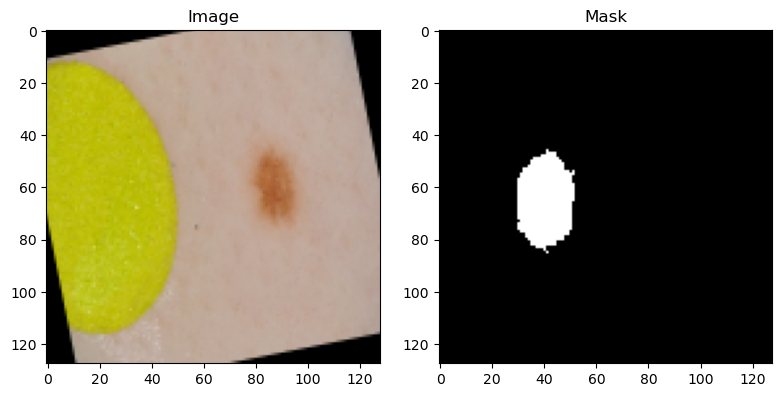

In [13]:
plot_img_mask_pred(train_dataset)

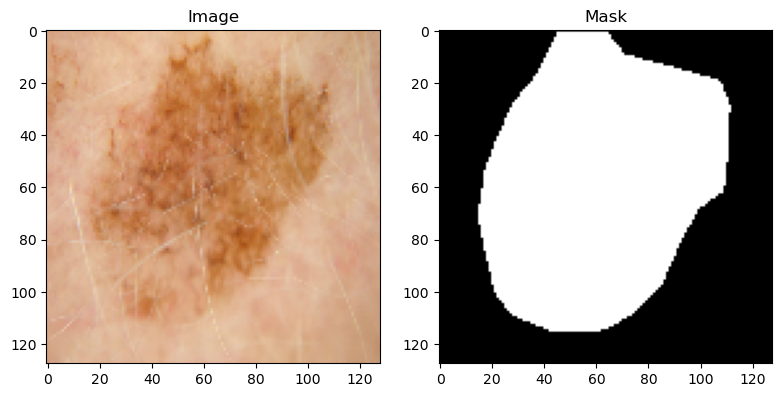

In [14]:
plot_img_mask_pred(val_dataset)

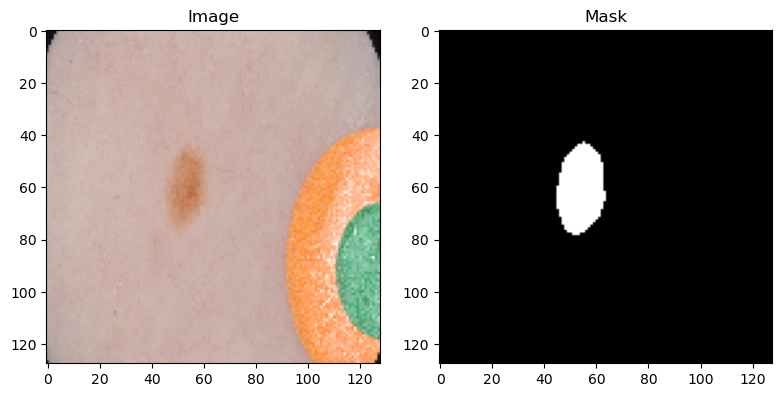

In [15]:
plot_img_mask_pred(test_dataset)

## U‑Net 模型定义

 ### 基础卷积块
- 结构：两个 3×3 卷积层，每个卷积后接 ReLU 激活，形成标准的“卷积‑激活‑卷积‑激活”模式。
- 关键设计：padding=1 确保特征图的空间尺寸在卷积前后保持不变（输入 H×W，输出 H×W）。这简化了跳跃连接时的尺寸对齐，避免了原版 U‑Net 中复杂的裁剪计算。
- 设备转移：to(device) 将张量移至 GPU（若可用），提高运算效率。



In [16]:
class Block(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, kernel_size=3,stride=1,padding=1)
        self.relu  = nn.ReLU()
        self.conv2 = nn.Conv2d(out_ch, out_ch, kernel_size=3,stride=1,padding=1)

    def forward(self, x):
        return self.relu(self.conv2(self.relu(self.conv1(x)))).to(device)
    

###  编码器（Encoder）
- 功能：逐步提取图像特征，同时通过池化降低空间分辨率，扩大感受野。
- 跳跃连接存储：每层卷积后的特征图被保存在 ftrs 列表中，供解码器后续拼接。

In [17]:
class Encoder(nn.Module):
    def __init__(self, chs=(3,64,128,256,512,1024)):
        super().__init__()
        self.enc_blocks = nn.ModuleList([Block(chs[i], chs[i+1]) for i in range(len(chs)-1)])
        self.pool = nn.MaxPool2d(2)

    def forward(self, x):
        ftrs = []
        for block in self.enc_blocks:
            x = block(x)
            ftrs.append(x)
            x = self.pool(x)
        return ftrs
    
    

### 解码器（Decoder）与裁剪函数 
- 上采样：使用转置卷积（ConvTranspose2d）将特征图尺寸加倍。
- 跳跃连接：通过中心裁剪 CenterCrop 将编码器对应层的特征图裁切至与当前解码器特征图相同尺寸，然后沿通道维度拼接，融合高层语义与低层细节信息。
- 裁剪原因：虽然我们使用 padding=1 保持了特征图尺寸，但池化操作会使得某些维度无法完全整除，导致尺寸略有偏差，因此需要显式裁剪保证拼接合法。

In [18]:
class Decoder(nn.Module):
    def __init__(self, chs=(1024, 512, 256, 128, 64)):
        super().__init__()
        self.chs  = chs
        self.upconvs  = nn.ModuleList([nn.ConvTranspose2d(chs[i], chs[i+1], 2, 2) for i in range(len(chs)-1)])
        self.dec_blocks = nn.ModuleList([Block(chs[i], chs[i+1]) for i in range(len(chs)-1)])

    def forward(self, x, encoder_features):
        for i in range(len(self.chs)-1):
            x  = self.upconvs[i](x)
            enc_ftrs = self.crop(encoder_features[i], x)
            x = torch.cat([x, enc_ftrs], dim=1)
            x = self.dec_blocks[i](x)
        return x

    def crop(self, enc_ftrs, x):
        _, _, H, W = x.shape
        enc_ftrs = transforms.CenterCrop([H, W])(enc_ftrs)
        return enc_ftrs
    
    

### 完整 U‑Net 模型
- enc_ftrs[::-1]：将编码器特征列表反转，使得解码器先从最深层特征开始上采样，逐步与浅层特征拼接。
- head：1×1 卷积层，将最终特征图通道数映射到 num_class=1（二分类：背景/病变），输出 logits（未经 Sigmoid 的概率）。

In [19]:
class UNet(nn.Module):
    def __init__(self, enc_chs=(3,64,128,256,512,1024), dec_chs=(1024, 512, 256, 128, 64), num_class=1):
        super().__init__()
        self.encoder = Encoder(enc_chs)
        self.decoder  = Decoder(dec_chs)
        self.head  = nn.Conv2d(dec_chs[-1], num_class, 1)


    def forward(self, x):
        enc_ftrs = self.encoder(x)
        out = self.decoder(enc_ftrs[::-1][0], enc_ftrs[::-1][1:])
        out = self.head(out)
        return out

## 模型训练

### 模型轻量化设计
实际使用的通道配置（In 21），原版 U‑Net 通道数为 (64,128,256,512,1024)，而本模型压缩为 (32,64,128,256)，参数量大幅降低。
**设计优势**
- 输入图像仅为 128×128，过深的通道数会导致大量冗余参数，且显存消耗巨大（RTX 5070 Ti 虽强，但仍需节省资源）。
- 增加 32 通道的起始层（原版为 64），在保持足够特征提取能力的同时进一步降低参数量。作者提及，加入 32 通道后模型性能有所提升，说明该层对边缘纹理的捕捉至关重要。
- padding=1 的使用保证了尺寸一致性，避免了原始论文中因无填充导致的尺寸缩小和复杂裁剪，使代码实现更简洁稳健。


In [20]:
# 实际使用的通道配置（In 21）
model = UNet(enc_chs=(3,32, 64,128,256), dec_chs=(256, 128, 64, 32), num_class=1)
optimizer = optim.Adam(model.parameters(), lr=learning_rate)
#optimizer = optim.RMSprop(model.parameters(), lr=learning_rate, weight_decay=learning_rate/epochs)
#optimizer = optim.SGD(model.parameters(), momentum=0.9, lr=learning_rate)
criterion = nn.BCEWithLogitsLoss()
#criterion = SoftBCEWithLogitsLoss()
#criterion = JaccardLoss()

scheduler = ReduceLROnPlateau(optimizer, factor=0.1, patience=5, mode='min')

In [21]:
model.to(device)

UNet(
  (encoder): Encoder(
    (enc_blocks): ModuleList(
      (0): Block(
        (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (relu): ReLU()
        (conv2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      )
      (1): Block(
        (conv1): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (relu): ReLU()
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      )
      (2): Block(
        (conv1): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (relu): ReLU()
        (conv2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      )
      (3): Block(
        (conv1): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (relu): ReLU()
        (conv2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      )
    )
    (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, 

In [22]:
print(torch.__version__)
print(torch.version.cuda)

2.7.1+cu128
12.8


In [23]:
summary(model, input_size=(batch_size,3, size[0],size[1]))


Layer (type:depth-idx)                   Output Shape              Param #
UNet                                     [16, 1, 128, 128]         --
├─Encoder: 1-1                           [16, 32, 128, 128]        --
│    └─ModuleList: 2-7                   --                        (recursive)
│    │    └─Block: 3-1                   [16, 32, 128, 128]        10,144
│    └─MaxPool2d: 2-2                    [16, 32, 64, 64]          --
│    └─ModuleList: 2-7                   --                        (recursive)
│    │    └─Block: 3-2                   [16, 64, 64, 64]          55,424
│    └─MaxPool2d: 2-4                    [16, 64, 32, 32]          --
│    └─ModuleList: 2-7                   --                        (recursive)
│    │    └─Block: 3-3                   [16, 128, 32, 32]         221,440
│    └─MaxPool2d: 2-6                    [16, 128, 16, 16]         --
│    └─ModuleList: 2-7                   --                        (recursive)
│    │    └─Block: 3-4              

In [24]:
train_loss_lst, valid_loss_lst, valid_acc_lst = train_model(model, epochs, train_dataloader, val_dataloader,
                                criterion, optimizer,device, scheduler=scheduler, scheduler_on='train_loss')
# scheduler_on='train_loss'：调度器基于训练损失进行触发（也可基于验证损失）

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/49 [00:00<?, ?it/s]

Epoch: 01/50 | Train Loss: 0.5974 | Validation Loss: 0.5108 | Validation Accuracy: 72.3%


  0%|          | 0/49 [00:00<?, ?it/s]

Epoch: 02/50 | Train Loss: 0.4563 | Validation Loss: 0.4886 | Validation Accuracy: 72.3%


...

Epoch: 48/50 | Train Loss: 0.1295 | Validation Loss: 0.1268 | Validation Accuracy: 94.3%


  0%|          | 0/49 [00:00<?, ?it/s]

Epoch: 49/50 | Train Loss: 0.1354 | Validation Loss: 0.1294 | Validation Accuracy: 94.1%


  0%|          | 0/49 [00:00<?, ?it/s]

Epoch: 50/50 | Train Loss: 0.1280 | Validation Loss: 0.1267 | Validation Accuracy: 94.3%


**三条曲线**
- 训练损失（Train Loss）：持续下降，从约 0.55 降至约 0.14，表明模型在训练集上学习良好。
- 验证损失（Validation Loss）：总体趋势下降，与训练损失保持接近，无明显过拟合（两者未出现大幅背离）。
- 验证准确率（Validation Accuracy）：从约 72% 上升至 94% 以上，展示了模型对病变区域分类的强大能力。

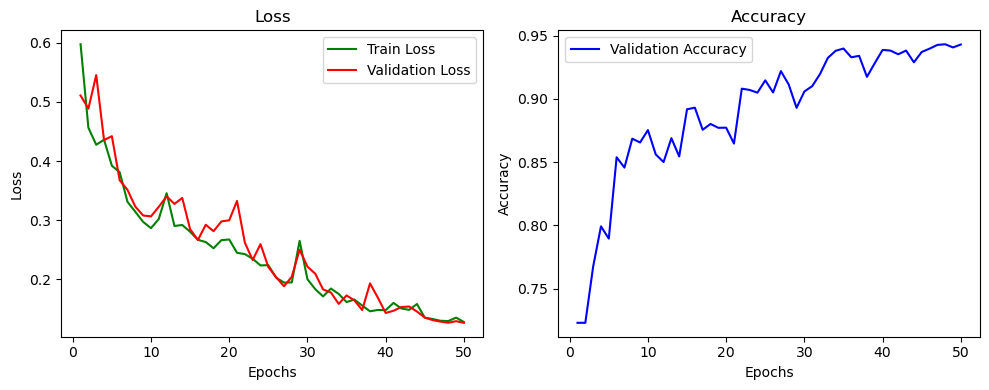

In [25]:
plot_loss_accuracy(train_loss_lst, valid_loss_lst, valid_acc_lst)

In [26]:
model.eval()

UNet(
  (encoder): Encoder(
    (enc_blocks): ModuleList(
      (0): Block(
        (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (relu): ReLU()
        (conv2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      )
      (1): Block(
        (conv1): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (relu): ReLU()
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      )
      (2): Block(
        (conv1): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (relu): ReLU()
        (conv2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      )
      (3): Block(
        (conv1): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (relu): ReLU()
        (conv2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      )
    )
    (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, 

## Saving part

This piece of code was necessary for me as I was saving different models while trying different parameters to be able to compare their performances.

In [27]:
# Save the model to your Google Drive
torch.save(model.state_dict(), './segmentation_model.pth')

In [28]:
# Initialize an empty model with the same architecture
upload_model = UNet(enc_chs=(3,32, 64,128,256), dec_chs=(256, 128, 64, 32), num_class=1)

In [29]:
# Load the model from Google Drive
model_path = './segmentation_model.pth'
upload_model.load_state_dict(torch.load(model_path,  map_location=torch.device('cpu')))
#upload_model.eval()
#upload_model.to(device)

<All keys matched successfully>

## Metrics

The metrics that are used to analyze the performance of the model for this task are fundamental for image segmentation models.

1. **Sensitivity (True Positive Rate, Recall):**
   - Sensitivity measures the ability of a segmentation model to correctly identify positive instances.
   - Formula: Sensitivity = (True Positives) / (True Positives + False Negatives)

2. **Specificity:**
   - Specificity measures the ability of a segmentation model to correctly identify negative instances.
   - Formula: Specificity = (True Negatives) / (True Negatives + False Positives)

3. **Pixel Accuracy:**
   - Pixel accuracy assesses the overall correctness of pixel-wise predictions.
   - Formula: Pixel Accuracy = (Correctly Classified Pixels) / (Total Pixels)

4. **Jaccard Score (Intersection over Union, IoU):**
   - The Jaccard Score calculates the intersection over the union of the predicted and ground truth segmentation masks.
   - Formula: IoU = (Intersection) / (Union)

5. **Dice Score (F1 Score):**
   - The Dice Score measures the similarity between the predicted and ground truth masks.
   - Formula: Dice Score = (2 * True Positives) / (2 * True Positives + False Positives + False Negatives)



In [30]:
sensetivity, specificity, accuracy, jaccard, dice = check_metrics(test_dataloader, model, device="cuda")

Sensitivity: 0.870221
Specificity: 0.976066
Pixel Accuracy: 0.957359
Jaccard Score: 0.806597
Dice Score: 0.885660


## Plotting the result

The graphs below demonstrate the performance of the model for one of the test samples. They provide a visual comparison between the predicted mask and the ground truth one.

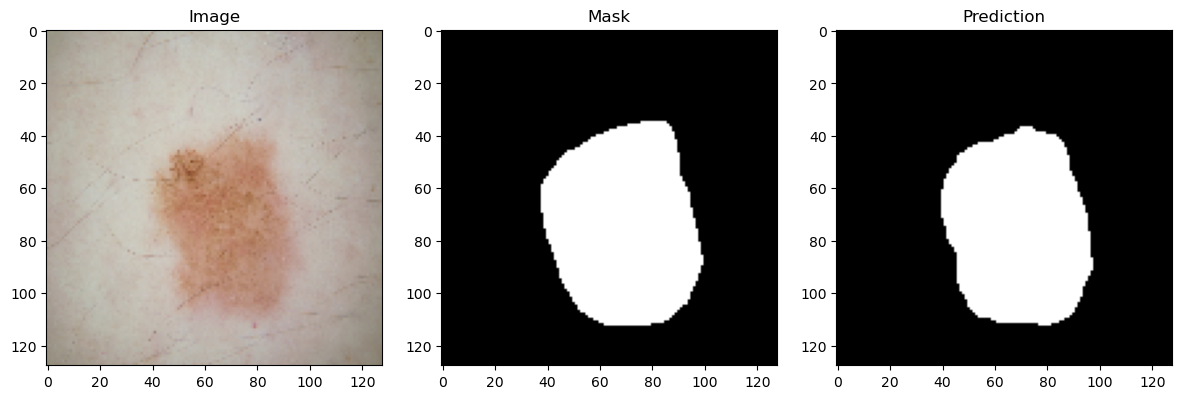

In [31]:
plot_img_mask_pred(test_dataset, plot_pred=True, model=model, device = "cuda")

## Results

The parameters I adjusted during the model training process are as follows:

1. Image size: I settled on a size of 128x128, as it had a minimal negative  impact on performance while significantly reducing memory usage.

2. Number of channels in the convolutional layers of the U-Net.

3. Learning rate, which I chose to decrease based on the loss function's behavior.

4. Batch  size: I opted for a relatively large batch size of 16 to expedite training without consuming excessive memory.

5. Loss function: I found that there was no noticeable difference between Soft BCE and BCE loss, and the model trained poorly with Jaccard.

6. Optimizer: I selected Adam as it was the fastest optimizer for this specific task.

7. Number of epochs: I tried to use as many epochs as possible (50), observing when the loss function almost stopped changing, indicating that the model had learned as much as possible.

8. Data augmentation: I applied standard image transformations for segmentation tasks, using a convenient library that could transform both the mask and the image simultaneously.

The final parameters can be found in the code within this notebook.